# 4. Offers in turn: negotiating the price of a ride

Examples of:

- the **ultimatum game**: what game theory predicts with one single offer, and what happens with passengers who care about fairness;
- the **Rubinstein model**: when offers go back and forth, **patience is power**;
- why the first offer is accepted immediately (complete information), and what a lie about one's patience would bring;
- how the non-cooperative approach meets the cooperative one: when waiting costs nothing, Rubinstein gives the **Nash solution** of chapter 1.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from bargain import *

---

## 4.1 One offer only: the ultimatum game

We go back to the ride of chapter 1: Alice drives to Valenciennes, picking up Bob costs her a 4 EUR detour, Bob's alternative is the train at 18 EUR.   Any contribution $c$ between 4 and 18 EUR is better than no deal for both: the **surplus is 14 EUR**.

This time Alice posts her ride on a carpool app with a **fixed price** ("take it or leave it"): Bob books it or not.  
If he does not, Alice drives alone and Bob takes the train: nobody gains anything, $d = (0, 0)$.

Game theory (backward induction): a "rational" Bob accepts any price below 18 EUR (a small gain is better than nothing), so Alice posts almost 18 EUR and keeps almost all the surplus.

But people are not like that. Let us model a population of passengers:
- 30 % are "rational": they accept any price below 18 EUR (they accept any share of the surplus, threshold 0);
- 70 % care about fairness: they refuse if their share of the surplus is below a personal threshold, between 10 % and 60 %.



In [3]:
TRAIN = 18
DETOUR = 4

`ultimatum_gain(share, thresholds)` gives Alice's mean share of the surplus when she leaves `share` of it to the passenger.

**Exercise 1**.  
Draw 10 000 thresholds with `np.random.default_rng(0)` (`rng.random`, `rng.uniform`),   
compute Alice's mean gain (in EUR: share × 14) for shares from 0 to 1 left to Bob,  
plot it, and find the best share and the corresponding **price**.

In [4]:
#set the random number generator for reproducibility
rng = np.random.default_rng(0)

In [5]:
#generate 10 random numbers uniformly distributed between 0.1 and 0.6
thresholds = rng.uniform(0.1, 0.6, 10)
print(thresholds)

[0.41848084 0.23489336 0.12048676 0.10826382 0.50663512 0.55637779
 0.40331789 0.46474828 0.3718125  0.56753621]


In [6]:
# gain of proposal Alice when she give a share of 0.2 (20% of 1) to passengers if all passengers care about fairness 
ultimatum_gain(0.2, thresholds)

0.16000000000000003

In [7]:
# gain of proposal Alice when she gives a share of 20% of the surplus to passengers if all passengers care about fairness
surplus = TRAIN - DETOUR
ultimatum_gain(0.2, thresholds) * surplus

2.24

In [8]:
# 5 passengers are rationnal, their thresholds are 0.0, 
# the other 5 passengers are fair and their thresholds are uniformly distributed between 0.1 and 0.6 
thresholds_fair = rng.uniform(0.1, 0.6, 5)
thresholds_rational = np.zeros(5)
thresholds = np.concatenate((thresholds_rational, thresholds_fair))
ultimatum_gain(0.2, thresholds) * surplus
#with rational passengers, Alice's gain is higher than with fair passengers.

7.839999999999999

In [ ]:
#your code here
#Draw 10 000 thresholds with between 0.1 and 0.6, 
# compute Alice's mean gain (in EUR: share × surplus) for shares from 0 to 1 left to Bob,
# and find the best share and the corresponding **price**.
# and plot the mean gain with
#plt.plot(TRAIN - shares * surplus, gains); 
#plt.axvline(TRAIN - best * surplus, ls=":", color="gray")
#plt.xlabel("price posted by Alice (EUR)"); plt.ylabel("Alice's mean gain (EUR)"); 
# plt.grid(alpha=.3); plt.show()


array([False,  True, False, False,  True, False, False, False,  True,
       False])

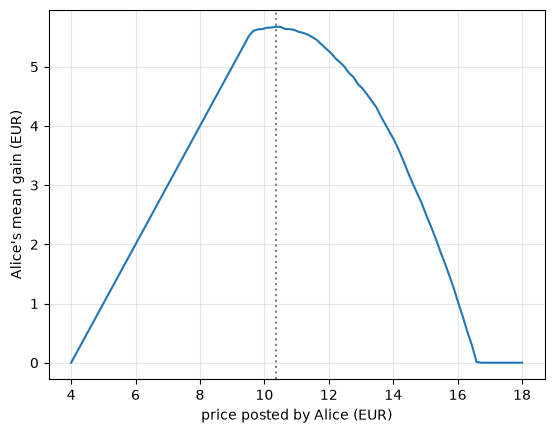

In [24]:
plt.plot(TRAIN - shares * surplus, gains); 
plt.axvline(TRAIN - best_share * surplus, ls=":", color="gray")
plt.xlabel("price posted by Alice (EUR)"); plt.ylabel("Alice's mean gain (EUR)"); plt.grid(alpha=.3)

**Reading.**   
Posting almost 18 EUR gives Alice only about 4 EUR on average:  only the "rational" passengers book.   
Her best price is about **11.8 EUR**, leaving Bob about 45 % of the surplus.   
The prediction "the proposer takes all" relies on a responder who accepts anything; 
fairness changes the best offer (experiments: offers around 40-50 %).

---

## 4.2 Offers in turn: the Rubinstein model

Now Alice and Bob chat: Alice proposes a price, Bob accepts or **refuses and proposes another price**, and so on, **without deadline**.

Why would Bob refuse? Because at the next round **he** proposes, and he can ask for a lower price.  
But each refused round is risky: Bob may lose the last train seats, Alice may take another passenger.

- $\delta_i$ = probability that the deal is still possible at the next round, for agent $i$ (its **patience**);
- utility of a gain $g$ obtained at round $t$: $u_i(g, t) = \delta_i^{\,t-1}\, g$;
- here Alice can wait ($\delta_1 = 0.9$), Bob less ($\delta_2 = 0.7$);
- it is a game with **complete information**: each one knows both $\delta_1$ and $\delta_2$.

Rubinstein (1982): let $x^*$ be the share of the surplus Alice keeps when **she** proposes, $y^*$ the share Bob keeps when **he** proposes.   
Each proposer offers just enough so that the other is indifferent between accepting now and refusing to propose at the next round:
$$1 - x^* = \delta_2\, y^* \qquad\qquad 1 - y^* = \delta_1\, x^*
\qquad\Rightarrow\qquad x^* = \frac{1-\delta_2}{1-\delta_1\delta_2}\qquad y^* = \frac{1-\delta_1}{1-\delta_1\delta_2}$$

**Exercise 2**.  
In the bargain library, function   `rubinstein(delta_1, delta_2)` return $x^*$ and $y^*$.  
Get  $x^*$ and $y^*$ for $\delta_1 = 0.9$, $\delta_2 = 0.7$,  
And write the price proposed by Alice if she start, and the share she keeps in €.  
And write the price proposed by Bob if she start, and the share he keeps in €.  

Check the two equations.

In [4]:
# Exercise 2: your code here

**Reading.**  
- Alice proposes **15.35 EUR**: she keeps 11.35 EUR of the surplus, Bob 2.65 EUR.  
- If Bob were the proposer, he would ask for 14.22 EUR.

---

## 4.3 Why Bob accepts at round 1

Rounds 2 and 3 are what *would* happen if offers were refused:

| round | proposer | price | Alice's gain | Bob's gain |
|---|---|---|---|---|
| 1 | Alice | 15.35 | 11.35 | 2.65 |
| 2 | Bob | 14.22 | 10.22 | 3.78 |
| 3 | Alice | 15.35 | 11.35 | 2.65 |

**Exercise 3**.  
Use the utility $u_i(g, t) = \delta_i^{\,t-1} g$ to answer:

1. at round 1, is accepting 2.65 EUR better for Bob than refusing to get 3.78 EUR at round 2?
2. Bob is greedy: he wants to refuse and propose **10 EUR** at round 2. Would Alice accept (compare her gain at 10 EUR with what she gets by refusing and proposing again at round 3)?
3. if she refuses, Bob only gets 2.65 EUR at round 3: what is it worth for him at round 1?

In [ ]:
# Exercise 3: your code here
# you can use this lambda function that computes the gain of a player given the gain, the turn and the discount factor
u = lambda gain, t, delta: delta ** (t - 1) * gain


In [30]:
#example : u(3.5, 2, 0.8) = 3.5*0.8^2, is the gain of a player who receives 3.5 EUR at turn 2 with a discount factor of 0.75
u(3.5, 2, 0.75)

2.625

1. Bob: accept now 2.65 | refuse -> 2.65 -> refusing brings nothing
2. Alice at 10 EUR gains 6 EUR; by refusing she gets 10.22 EUR -> she refuses
3. Bob gets 2.65 EUR at round 3, worth 1.30 EUR at round 1 (< 2.65)


**Reading.**

1. $0.7 \times 3.78 = 2.65$: refusing gives Bob exactly what Alice offers, with more risk. He accepts.
2. At 10 EUR Alice would gain 6 EUR, but by refusing she can expect $0.9 \times 11.35 = 10.22$ EUR: **she refuses**.  
The highest price Bob can obtain at round 2 is 14.22 EUR.
3. After two risky rounds, Bob's 2.65 EUR are worth only $0.7^2 \times 2.65 = 1.30$ EUR.  
Being greedy is **worse** than accepting.

The threat of the next rounds sets the price, even if they never happen.  
And everything happens at round 1 because each one **knows** the other's patience: there is nothing to discover.

---

## 4.4 Patience is power

**Exercise 4**.  
Draw the price $c^* = 4 + 14\,x^*$ proposed by Alice as a function of $\delta_1$ and $\delta_2$ between 0.05 and 0.99 
Draw the level line $c^* = 11$ EUR (the Nash price of chapter 1).

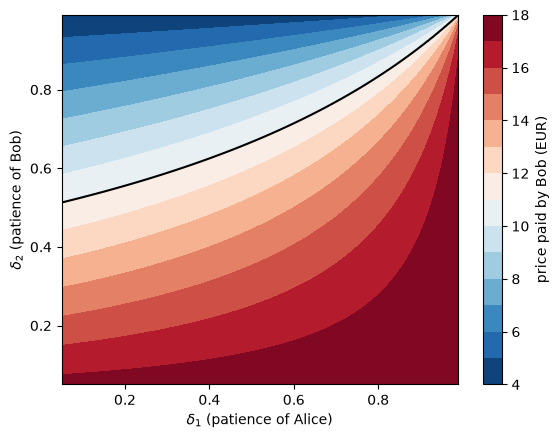

In [ ]:
#a simple solution that use python  graphical lib
#I've made it for you, but you can try to do it by yourself if you want to practice your python skills
#
#
#
#
#
#
deltas = np.linspace(0.05, 0.99, 95)
D1, D2 = np.meshgrid(deltas, deltas)
#D1 is a grid of patience values for Alice, D2 is a grid of patience values for Bob
#python can make operation on array, matrices, etc. so we can compute the price proposed by Alicefor all combinations of patience in 1 call
price = DETOUR + (TRAIN - DETOUR) * rubinstein(D1, D2)[0]
##graphical representation of the price proposed by Alice for all combinations of patience values
cs = plt.contourf(D1, D2, price, levels=np.arange(4, 18.5, 1), cmap="RdBu_r")
plt.contour(D1, D2, price, levels=[11], colors="k")
plt.colorbar(cs, label="price paid by Bob (EUR)")
plt.xlabel("$\\delta_1$ (patience of Alice)"); plt.ylabel("$\\delta_2$ (patience of Bob)"); plt.show()

**Reading.**   
The more patient agent gets the larger share.   
When Bob is in a hurry ($\delta_2$ small), the price goes up to 18 EUR; when Alice is in a hurry, it goes down towards 4 EUR.  
The black line (11 EUR) lies slightly above the diagonal: with equal patience, the first proposer (Alice) has a small advantage.

---

## 4.5 From one offer to no risk at all

**Exercise 5**.  
Take the same patience for both, $\delta_1 = \delta_2 = \delta$,  
and plot the price $c^*$ for $\delta$ from 0 to 0.999.  
What happens at both ends?

In [10]:
# Exercise 5: your code here

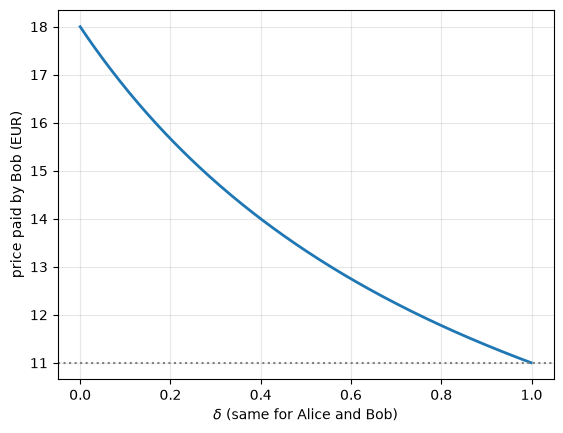

**Reading.** $c^* = 4 + \frac{14}{1 + \delta}$.

- $\delta \to 0$: a refusal ends everything, this is the **ultimatum game** (4.1 with a rational Bob): Alice posts 18 EUR.
- $\delta \to 1$: refusing is almost free, the price tends to **11 EUR**, the **Nash solution**.

The non-cooperative model (a protocol) and the cooperative one (axioms) meet: this is the *Nash solution*.

---

## 4.6 Explore: what if Bob lies about his patience?

The model assumes that both patiences are known.  
If Bob can **announce** his patience, he may lie: he is in a hurry ($\delta_2 = 0.7$) but says he can wait.

**Exercise 6**.  
Suppose Alice believes Bob's announcement and proposes the Rubinstein price computed with the announced $\delta_2$.   
For an announced $\delta_2$ from 0.7 to 0.95, how much does Bob gain by lying?   
Why should Alice not believe a free announcement, and what could make an announcement credible?

In [12]:
# Exercise 6: your code here

announced delta2 = 0.70: price 15.35 EUR, Bob gains 2.65 EUR (+0.00 by lying)
announced delta2 = 0.75: price 14.77 EUR, Bob gains 3.23 EUR (+0.58 by lying)
announced delta2 = 0.80: price 14.00 EUR, Bob gains 4.00 EUR (+1.35 by lying)
announced delta2 = 0.85: price 12.94 EUR, Bob gains 5.06 EUR (+2.42 by lying)
announced delta2 = 0.90: price 11.37 EUR, Bob gains 6.63 EUR (+3.98 by lying)
announced delta2 = 0.95: price 8.83 EUR, Bob gains 9.17 EUR (+6.52 by lying)


**Reading.**  
Saying "I can wait" ($\delta_2 = 0.9$) lowers the price from 15.35 to 11.37 EUR: Bob gains 4 EUR by lying.  
Since everyone has an interest in pretending to be patient, a free announcement is **not credible**.  
What counts are costly or verifiable signals:   
refusing and really waiting (only a patient agent can afford it, but this creates delays and failures),  
a proof (a train ticket already bought),  
or a reputation when agents meet often.  
This is why negotiating agents use **concession strategies** rather than Rubinstein's formula.

---


## Key points

| Model | Prediction | What drives the split |
|---|---|---|
| ultimatum, rational passenger | Alice posts almost 18 EUR | who makes the only offer |
| ultimatum, fair passengers | best price about 11.8 EUR | fear of a refusal |
| Rubinstein ($\delta_1 = 0.9$, $\delta_2 = 0.7$) | price 15.35 EUR, accepted at round 1 | **patience**: the more patient gets more |
| Rubinstein, $\delta \to 0$ | ultimatum | |
| Rubinstein, $\delta \to 1$ | Nash solution (11 EUR) | |
| private patience | lies, delays, failures | credibility of the signals |